In [14]:
import time
import os
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

%matplotlib inline

from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)
from xgboost import XGBRegressor

# Load processed data from T04

data_dir = "../../Feature Engineering/data_processed"

data_train = pd.read_csv(
    os.path.join(data_dir, "data_train.csv")
)

data_test = pd.read_csv(
    os.path.join(data_dir, "data_test.csv")
)

print("Train shape:", data_train.shape)
print("Test shape:", data_test.shape)



Train shape: (9995, 135)
Test shape: (2499, 135)


In [15]:
# Separate features and target

target = "price_million"

X_train = data_train.drop(columns=[target])
y_train = data_train[target]

X_test = data_test.drop(columns=[target])
y_test = data_test[target]

# Validate feature consistency

assert list(X_train.columns) == list(X_test.columns), \
    "Train and test features do not match!"

assert not X_train.isna().any().any(), \
    "Training data contains missing values!"

assert not X_test.isna().any().any(), \
    "Testing data contains missing values!"

assert (y_train >= 0).all(), \
    "Training target contains negative prices!"

assert (y_test >= 0).all(), \
    "Testing target contains negative prices!"

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nMissing values:")
print("Train:", X_train.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

print("\nTarget statistics:")
print(y_train.describe())
non_numeric = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

assert len(non_numeric) == 0, \
    f"Non-numeric features found: {non_numeric}"

assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()
assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_test.to_numpy()).all()

print("Data validation passed!")

X_train: (9995, 134)
X_test: (2499, 134)

Missing values:
Train: 0
Test: 0

Target statistics:
count     9995.000000
mean       513.155361
std        390.178024
min         20.000000
25%        278.000000
50%        435.000000
75%        635.000000
max      10900.000000
Name: price_million, dtype: float64
Data validation passed!


**Kiểm tra dữ liệu:** 9.995 xe train, 2.499 xe test, 134 đặc trưng, không thiếu dữ liệu, toàn bộ là số. Giá xe lệch phải nên mô hình sẽ học trên giá đã log.

In [16]:
# Baseline XGBoost

xgb = TransformedTargetRegressor(
    regressor=XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, pred_xgb))
xgb_mae = mean_absolute_error(y_test, pred_xgb)
xgb_r2 = r2_score(y_test, pred_xgb)

print("XGBoost Baseline")
print("RMSE:", round(xgb_rmse, 1), "million VND")
print("MAE :", round(xgb_mae, 1), "million VND")
print("R2  :", round(xgb_r2, 3))

XGBoost Baseline
RMSE: 214.0 million VND
MAE : 84.7 million VND
R2  : 0.739


**Baseline XGBoost:** dùng tham số khởi đầu phổ biến để làm mốc so sánh. `TransformedTargetRegressor` tự log giá khi học và đổi ngược khi dự đoán, nên các chỉ số tính bằng triệu VND.

Kết quả: RMSE 214,0 · MAE 84,7 · R² 0,739.

In [17]:
# XGBoost Hyperparameter Tuning

xgb_search = TransformedTargetRegressor(
    regressor=XGBRegressor(
        random_state=42,
        n_jobs=-1
    ),
    func=np.log1p,
    inverse_func=np.expm1
)

xgb_params = {
    "regressor__n_estimators": [300, 600, 900],
    "regressor__learning_rate": [0.03, 0.05, 0.1],
    "regressor__max_depth": [4, 6, 8],
    "regressor__subsample": [0.7, 0.9, 1.0],
    "regressor__colsample_bytree": [0.5, 0.8, 1.0]
}

start_time = time.time()

search = RandomizedSearchCV(
    estimator=xgb_search,
    param_distributions=xgb_params,
    n_iter=10,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_

tuning_time = (time.time() - start_time) / 60

best_params = search.best_params_
best_cv_rmse = -search.best_score_

print("XGBoost Tuned")
print("\nBest parameters:")
print(best_params)

print("CV RMSE:", round(best_cv_rmse, 2))
print("Tuning time:", round(tuning_time, 2), "minutes")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
XGBoost Tuned

Best parameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 600, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 1.0}
CV RMSE: 206.7
Tuning time: 1.73 minutes


In [18]:
# Evaluate XGBoost Tuned

pred_xgb_tuned = best_model.predict(X_test)

xgb_tuned_rmse = np.sqrt(
    mean_squared_error(y_test, pred_xgb_tuned)
)

xgb_tuned_mae = mean_absolute_error(
    y_test, pred_xgb_tuned
)

xgb_tuned_r2 = r2_score(
    y_test, pred_xgb_tuned
)

print("XGBoost Tuned")
print("RMSE:", round(xgb_tuned_rmse, 3), "million VND")
print("MAE :", round(xgb_tuned_mae, 3), "million VND")
print("R2  :", round(xgb_tuned_r2, 3))

XGBoost Tuned
RMSE: 206.93 million VND
MAE : 79.752 million VND
R2  : 0.755


**Tuning:** `RandomizedSearchCV` thử 10 trong 243 bộ tham số, chấm bằng cross-validation 3 phần trên tập train (không dùng tập test). Bộ tốt nhất: 600 cây, `max_depth=8`, `learning_rate=0.1`, `subsample=0.9`, `colsample_bytree=1.0`, CV RMSE 206,7.

Trên tập test, bản tuned đạt RMSE 206,93 · MAE 79,75 · R² 0,755, tốt hơn baseline (RMSE 214,0). Mức cải thiện từ tuning không lớn.

In [19]:
# Compare Linear Regression and XGBoost Tuned

# Load Linear Regression metrics from T05
t05_metrics_path = "../T05/t05_metrics.csv"

t05_metrics = pd.read_csv(
    t05_metrics_path,
    encoding="utf-8-sig"
)

# Get Linear Regression test results
lr_test = t05_metrics[
    t05_metrics["Mô hình / tập"] == "Linear Regression - test"
].iloc[0]

# Compare both models
results = [
    {
        "Model": "Linear Regression",
        "RMSE": lr_test["RMSE (triệu)"],
        "MAE": lr_test["MAE (triệu)"],
        "R2": lr_test["R²"]
    },
    {
        "Model": "XGBoost Baseline",
        "RMSE": xgb_rmse,
        "MAE": xgb_mae,
        "R2": xgb_r2
    },
    {
        "Model": "XGBoost Tuned",
        "RMSE": xgb_tuned_rmse,
        "MAE": xgb_tuned_mae,
        "R2": xgb_tuned_r2
    }
]

results_df = pd.DataFrame(results)

print("Model Performance Comparison")
print(results_df.round(3).to_string(index=False))

Model Performance Comparison
            Model   RMSE     MAE    R2
Linear Regression 243.70 103.100 0.661
 XGBoost Baseline 213.97  84.677 0.739
    XGBoost Tuned 206.93  79.752 0.755


**So sánh mô hình:** XGBoost tuned có R² 0,755 và RMSE 206,93, trong khi Linear Regression có R² 0,661 và RMSE 243,7. XGBoost giảm RMSE khoảng 15% so với Linear Regression.

In [20]:
# Select and save the final model

best_name = "XGBoost Tuned"

print("Selected model:", best_name)
print("CV RMSE:", round(best_cv_rmse, 2))

print("\nBest parameters:")
print(best_params)

joblib.dump(best_model, "best_model.pkl")

print("\nModel saved as best_model.pkl")

Selected model: XGBoost Tuned
CV RMSE: 206.7

Best parameters:
{'regressor__subsample': 0.9, 'regressor__n_estimators': 600, 'regressor__max_depth': 8, 'regressor__learning_rate': 0.1, 'regressor__colsample_bytree': 1.0}

Model saved as best_model.pkl


**Chọn mô hình cuối:** chọn XGBoost tuned vì có test RMSE thấp nhất (206,93) so với XGBoost baseline (214,0) và Linear Regression (243,7). Mô hình được lưu vào `best_model.pkl`.

In [21]:
# T08: Model Interpretation & Error Analysis

# Confirm that the selected model supports feature importance
assert hasattr(best_model.regressor_, "feature_importances_"), \
    "Selected model does not support feature importance!"

# Reuse the selected model and existing test data
assert X_test.shape[0] == y_test.shape[0]

# Generate predictions using the selected model
y_pred = best_model.predict(X_test)

# Calculate residuals
residuals = y_test - y_pred
abs_errors = residuals.abs()

# Calculate evaluation metrics
t08_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
t08_mae = mean_absolute_error(y_test, y_pred)
t08_r2 = r2_score(y_test, y_pred)

print("T08 - Selected Model:", best_name.upper())
print("RMSE:", round(t08_rmse, 3), "million VND")
print("MAE :", round(t08_mae, 3), "million VND")
print("R2  :", round(t08_r2, 3))
print("Test samples:", len(y_test))

T08 - Selected Model: XGBOOST TUNED
RMSE: 206.93 million VND
MAE : 79.752 million VND
R2  : 0.755
Test samples: 2499


Residual Statistics:
Mean residual: 18.8
Median residual: 1.12
Mean absolute residual: 79.75


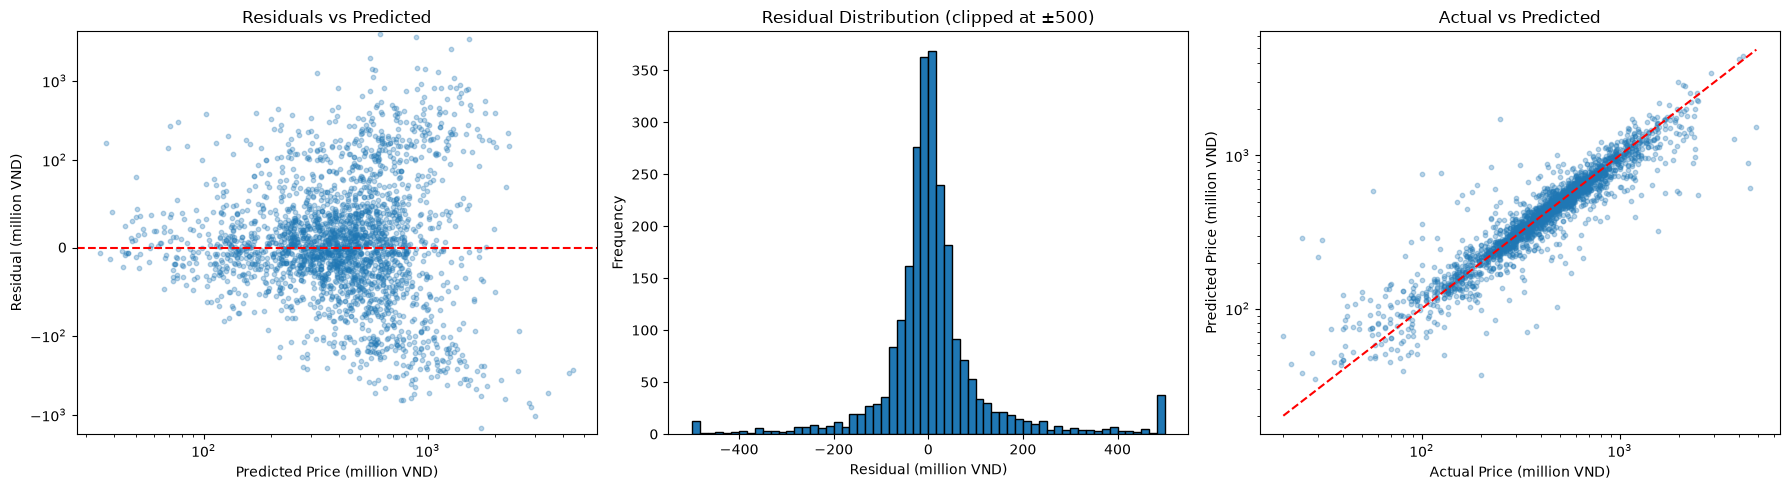

In [22]:
# Calculate residual statistics
print("Residual Statistics:")
print("Mean residual:", round(residuals.mean(), 2))
print("Median residual:", round(residuals.median(), 2))
print("Mean absolute residual:", round(abs_errors.mean(), 2))

# Visualize residuals
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 1. Residuals vs Predicted
ax[0].scatter(y_pred, residuals, alpha=0.3, s=10)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_xscale("log")
ax[0].set_yscale("symlog", linthresh=100)
ax[0].set_title("Residuals vs Predicted")
ax[0].set_xlabel("Predicted Price (million VND)")
ax[0].set_ylabel("Residual (million VND)")

# 2. Residual Distribution
ax[1].hist(
    residuals.clip(-500, 500),
    bins=60,
    edgecolor="black"
)
ax[1].set_title("Residual Distribution (clipped at ±500)")
ax[1].set_xlabel("Residual (million VND)")
ax[1].set_ylabel("Frequency")

# 3. Actual vs Predicted
ax[2].scatter(y_test, y_pred, alpha=0.3, s=10)

lim = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

ax[2].plot(lim, lim, color="red", linestyle="--")
ax[2].set_xscale("log")
ax[2].set_yscale("log")
ax[2].set_title("Actual vs Predicted")
ax[2].set_xlabel("Actual Price (million VND)")
ax[2].set_ylabel("Predicted Price (million VND)")

plt.tight_layout()
plt.show()

**Residual:** residual = giá thật − giá dự đoán, nên giá trị dương nghĩa là mô hình đoán thấp hơn giá thật. Trung vị +1,1 triệu cho thấy hầu hết xe được đoán khá đúng; trung bình +19 bị kéo lên bởi một số xe đắt bị đoán thấp. Biểu đồ dùng trục log/symlog vì giá trải rộng.

In [23]:
# Calculate percentage errors
residual_pct = residuals / y_test * 100

# Define price ranges
bins = [0, 200, 400, 700, 1000, np.inf]

labels = [
    "<200",
    "200-400",
    "400-700",
    "700-1000",
    ">1000"
]

price_band = pd.cut(
    y_test,
    bins=bins,
    labels=labels
)

# Group errors by actual price range
error_by_band = pd.DataFrame({
    "Price Band": price_band,
    "Absolute Error": abs_errors,
    "Percentage Error": residual_pct.abs(),
    "Residual": residuals
}).groupby("Price Band", observed=True).agg(
    Samples=("Absolute Error", "size"),
    MAE=("Absolute Error", "mean"),
    MAPE=("Percentage Error", "mean"),
    Mean_Residual=("Residual", "mean")
).round(2)

print("Error Analysis by Price Range:")
print(error_by_band)

Error Analysis by Price Range:
            Samples     MAE   MAPE  Mean_Residual
Price Band                                       
<200            372   39.93  42.59         -22.76
200-400         756   40.21  13.41          -7.28
400-700         849   55.19  10.47           1.72
700-1000        295   96.08  11.60          25.87
>1000           227  347.35  20.02         228.50


**Sai số theo phân khúc giá:** mô hình ổn nhất ở phân khúc 200–1.000 triệu (MAPE khoảng 10–13%). Kém hơn ở xe dưới 200 triệu (MAPE khoảng 43%) và trên 1 tỷ (MAE khoảng 347 triệu, thường bị đoán thấp), vì phân khúc trên 1 tỷ ít mẫu và giá biến động mạnh.

Built-in Feature Importance:
carmodel_grouped       0.4278
carbrand_grouped       0.3333
gearbox                0.0599
fuel                   0.0576
cartype                0.0537
car_age                0.0270
carorigin              0.0222
region_grouped         0.0119
flag_zin               0.0024
odo_km                 0.0016
km_per_year            0.0012
flag_chinh_chu         0.0010
flag_bao_duong_hang    0.0005
dtype: float32


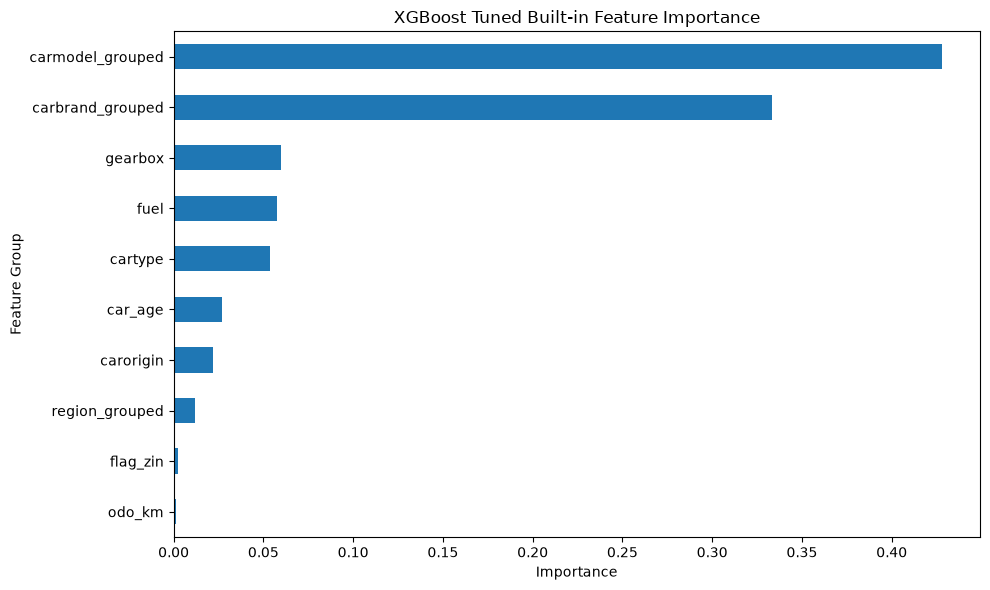

In [24]:
# Get feature importance from the selected model
feature_importance = pd.Series(
    best_model.regressor_.feature_importances_,
    index=X_test.columns
)

# Group one-hot encoded categorical features
cat_prefixes = [
    "carbrand_grouped",
    "carmodel_grouped",
    "region_grouped",
    "gearbox",
    "fuel",
    "cartype",
    "carorigin"
]

def group_of(col):
    for prefix in cat_prefixes:
        if col.startswith(prefix + "_"):
            return prefix
    return col

# Aggregate importance by feature group
builtin_importance = (
    feature_importance
    .groupby(group_of)
    .sum()
    .sort_values(ascending=False)
)

print("Built-in Feature Importance:")
print(builtin_importance.head(15).round(4))

# Plot top 10 features
plt.figure(figsize=(10, 6))

builtin_importance.head(10).sort_values().plot(
    kind="barh"
)

plt.title(f"{best_name} Built-in Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature Group")
plt.tight_layout()
plt.show()

**Built-in importance:** dòng xe (carmodel) và hãng xe (carbrand) đứng đầu. Khi gộp các cột One-Hot thành một nhóm bằng cách cộng điểm, nhóm có nhiều cột (như carmodel, 66 cột) bị thổi phồng, nên thứ hạng này chỉ để tham khảo.

Grouped Permutation Importance:
carbrand_grouped       223.20
car_age                153.08
carmodel_grouped        72.96
gearbox                 43.80
odo_km                  25.91
cartype                 15.29
fuel                    13.86
km_per_year              8.05
region_grouped           6.29
carorigin                6.14
flag_chinh_chu           0.10
flag_zin                 0.00
flag_bao_duong_hang     -0.01
dtype: float64


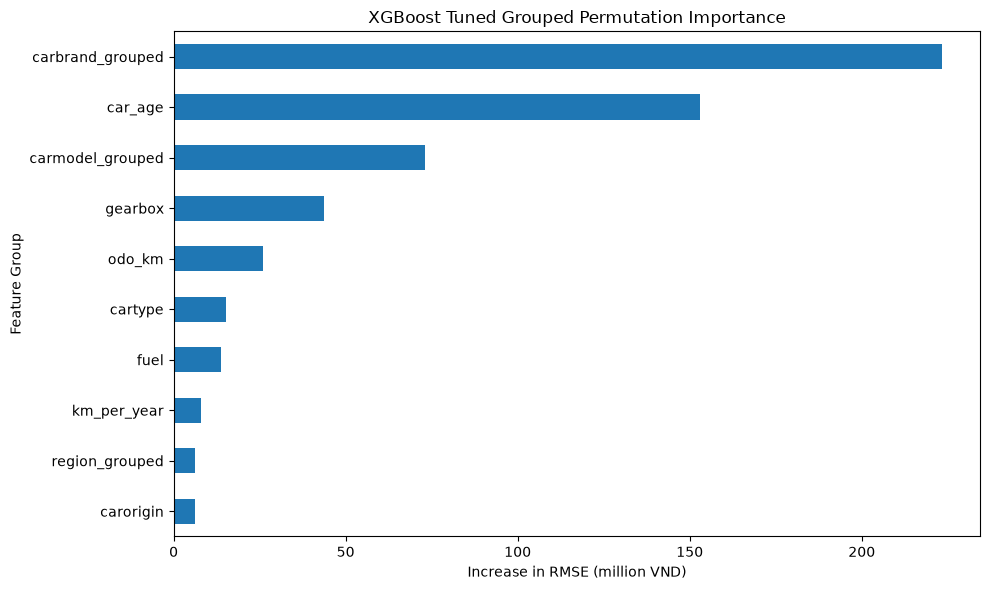

In [25]:
# Group columns by feature
groups = {}

for col in X_test.columns:
    group = group_of(col)
    groups.setdefault(group, []).append(col)

# Calculate baseline RMSE
base_rmse = np.sqrt(
    mean_squared_error(y_test, best_model.predict(X_test))
)

# Grouped permutation importance
rng = np.random.RandomState(42)

group_perm = {}

for group, cols in groups.items():

    scores = []

    for _ in range(5):

        X_permuted = X_test.copy()

        # Shuffle the entire feature group
        permutation = rng.permutation(len(X_permuted))

        X_permuted[cols] = (
            X_permuted[cols]
            .iloc[permutation]
            .to_numpy()
        )

        # Calculate RMSE increase
        permuted_pred = best_model.predict(X_permuted)

        permuted_rmse = np.sqrt(
            mean_squared_error(y_test, permuted_pred)
        )

        scores.append(permuted_rmse - base_rmse)

    group_perm[group] = np.mean(scores)

group_perm = pd.Series(group_perm).sort_values(
    ascending=False
)

print("Grouped Permutation Importance:")
print(group_perm.round(2))

# Visualize top 10 groups
plt.figure(figsize=(10, 6))

group_perm.head(10).sort_values().plot(
    kind="barh"
)

plt.title(f"{best_name} Grouped Permutation Importance")
plt.xlabel("Increase in RMSE (million VND)")
plt.ylabel("Feature Group")

plt.tight_layout()
plt.show()

**Grouped Permutation Importance:** đo mức tăng RMSE trên tập test khi xáo trộn cả một nhóm cột. Hãng xe (+223 triệu) và tuổi xe (+153 triệu) đóng góp nhiều nhất vào dự đoán; các cột cờ (flag) gần như không đóng góp. Đây là mức đóng góp cho dự đoán của mô hình, không chứng minh quan hệ nhân quả.

In [26]:
print("=" * 50)
print("T08 - FINAL MODEL ANALYSIS")
print("=" * 50)

print("\nSelected Model:", best_name.upper())

print("\nOverall Performance:")
print("RMSE:", round(t08_rmse, 2), "million VND")
print("MAE :", round(t08_mae, 2), "million VND")
print("R2  :", round(t08_r2, 3))

print("\nTop 5 Built-in Features:")
print(builtin_importance.head(5).round(4))

print("\nTop 5 Grouped Permutation Features:")
print(group_perm.head(5).round(2))

print("\nError by Price Range:")
print(error_by_band)

print("\nT08 Analysis Completed!")

T08 - FINAL MODEL ANALYSIS

Selected Model: XGBOOST TUNED

Overall Performance:
RMSE: 206.93 million VND
MAE : 79.75 million VND
R2  : 0.755

Top 5 Built-in Features:
carmodel_grouped    0.4278
carbrand_grouped    0.3333
gearbox             0.0599
fuel                0.0576
cartype             0.0537
dtype: float32

Top 5 Grouped Permutation Features:
carbrand_grouped    223.20
car_age             153.08
carmodel_grouped     72.96
gearbox              43.80
odo_km               25.91
dtype: float64

Error by Price Range:
            Samples     MAE   MAPE  Mean_Residual
Price Band                                       
<200            372   39.93  42.59         -22.76
200-400         756   40.21  13.41          -7.28
400-700         849   55.19  10.47           1.72
700-1000        295   96.08  11.60          25.87
>1000           227  347.35  20.02         228.50

T08 Analysis Completed!
